In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
from PIL import Image


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF  import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from FWHM_treatment_func import *
import FWHM_treatment_func
importlib.reload(FWHM_treatment_func)
from FWHM_treatment_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_plot
importlib.reload(PaP_quantitative_study_plot)
from PaP_quantitative_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_func
importlib.reload(PaP_quantitative_study_func)
from PaP_quantitative_study_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *

from Spectra_plotting import *
import Spectra_plotting
importlib.reload(Spectra_plotting)
from Spectra_plotting  import *


import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

import matplotlib.animation as animation


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Illustrations')
import gif_func
importlib.reload(gif_func)
from gif_func import *


cm = 1/2.54  # centimeters in inches
import matplotlib as mpl


fixed_factor = 0.8 #Origin fixed factor for police size
figsize_conversion_coeff =  1.381 # To have matching graph size with origin
mpl.rcParams["font.size"] = 20*fixed_factor
mpl.rcParams['axes.linewidth'] = 1.5 #graph border lines width
mpl.rcParams['font.family'] = 'Arial'




dir_save_data = r'H:\commun\Utilisateur FNO\Nathan\Articles\Optical detection\Figures\Python'
saving_figures = False

# Figure 1 : sample presentation

## All PaP signals together : Nd on Sapphire studied in 2025

In [16]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'

os.chdir(dir_root)



# get calib
dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\Octobre 2024'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']

WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


## Get all traces
All_traces = {}


for root, dirs, files in os.walk(dir_root) :
    for dir in dirs :
        if dir.endswith('treated') :
            Trace_acoustic = get_PaP_dataset(dir_root + '\\' + dir, 'Trace_acoustic_fitted')
            Trace_acoustic.lda_probe = int(dir.split('_')[-2])


            #Get probe FWHM
            idx_fwhm_probe =  np.searchsorted(WL_calib_probe,Trace_acoustic.lda_probe)
            fwhm_probe = FWHM_calib_probe[idx_fwhm_probe]

            coeff = DTT_to_delta_sigma(1, fwhm_probe) 
            
            Trace_acoustic.dtt_to_sigma_ext_coeff = coeff
            print(Trace_acoustic.lda_probe, coeff)
            All_traces[Trace_acoustic.dir_name] = Trace_acoustic


580 -147944.46037545914
590 -159567.24705257438
720 -209896.89086247204
660 -186962.58575057233
640 -184587.61252134998
700 -203933.99845391957
710 -208225.71113093922
650 -188219.37519454
670 -186999.9016906599
680 -189030.03162651492
690 -200513.55149086233
600 -164212.02184506867
610 -169716.30234597126
620 -181158.69367665632
630 -180981.23070935957


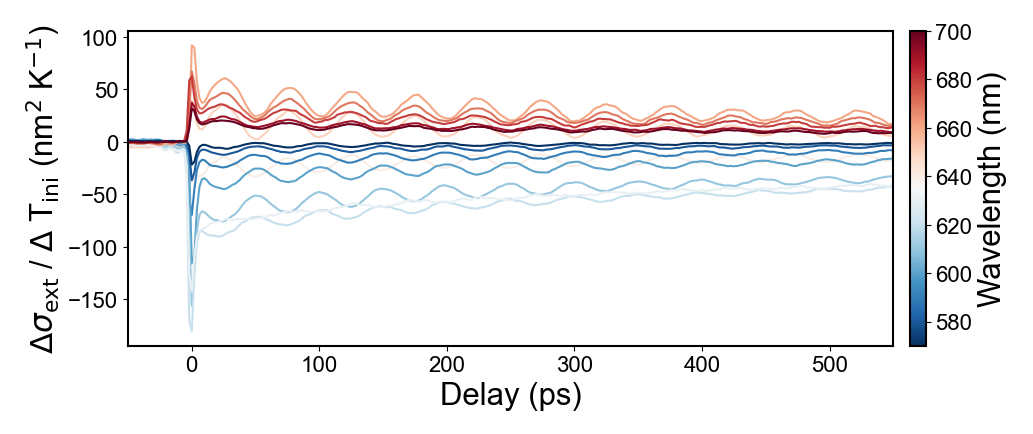

In [ ]:
fig, ax = plt.subplots(figsize=(18*cm*figsize_conversion_coeff, 8*cm*figsize_conversion_coeff))

# Collect lda_probe values
lda_values = np.array([All_traces[key].lda_probe for key in All_traces])

# Colormap and normalization (explicit range)
cmap = plt.get_cmap('copper')
cmap = plt.get_cmap('RdBu')
cmap = plt.get_cmap('seismic')
#cmap = plt.get_cmap('twilight')
cmap = plt.get_cmap('RdBu_r')
norm = plt.Normalize(vmin=lda_values.min(), vmax=lda_values.max())

# Plot traces
for key in All_traces:
    trace = All_traces[key]
    ax.plot(
        trace.delay_tot,
        trace.DTT_tot*trace.dtt_to_sigma_ext_coeff,
        color=cmap(norm(trace.lda_probe))
    )

# Create a ScalarMappable for the colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])  # required for older matplotlib versions

# Add colorbar on the side, tied to ax
cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02,      # distance from the plot
    fraction=0.05 # width of the colorbar
)

cbar.set_label(r'Wavelength (nm)', fontsize=28*fixed_factor)

ax.set_xlabel('Delay (ps)', fontsize=28*fixed_factor)
ax.set_ylabel(r'$\Delta \sigma_{\mathrm{ext}}$ / $\Delta$ T$_{\mathrm{ini}}$ (nm$^2$ K$^{-1}$)', fontsize=28*fixed_factor)
ax.set_xlim( (-50, 550))



fig.set_size_inches((19*cm*figsize_conversion_coeff, 8*cm*figsize_conversion_coeff))
plt.tight_layout()
plt.show()


fig.patch.set_facecolor( '#FF000000' )

if saving_figures :
    os.chdir(dir_save_data)
    plt.savefig('All raw PaP signals - NDe thick sapphire.svg')
    plt.savefig('All raw PaP signals - NDe thick sapphire.png')

## All PaP signals together : ND2 zone1 on thick Silica studied in April 2026

In [5]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D2 zone1\PaP_study'

os.chdir(dir_root)



# get calib
dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\2026-04'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_1D_mean']

WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


## Get all traces
All_traces = {}


for root, dirs, files in os.walk(dir_root) :
    for dir in dirs :
        if dir.endswith('treated') :
            Trace_acoustic = get_PaP_dataset(dir_root + '\\' + dir, 'Trace_acoustic_fitted')
            Trace_acoustic.lda_probe = int(dir.split('_')[-2])


            #Get probe FWHM
            idx_fwhm_probe =  np.searchsorted(WL_calib_probe,Trace_acoustic.lda_probe)
            fwhm_probe = FWHM_calib_probe[idx_fwhm_probe]

            coeff = DTT_to_delta_sigma(1, fwhm_probe) 
            
            Trace_acoustic.dtt_to_sigma_ext_coeff = coeff
            print(Trace_acoustic.lda_probe, coeff)
            All_traces[Trace_acoustic.dir_name] = Trace_acoustic

dT1 = 7.19079187151164 # Heat rise for probe 650nm and below
dT2 = 8.93354044732574 # Heat rise for probe 660nm and higher


640 -189513.15978932692
650 -196829.84188182733
590 -160188.77820316196
600 -163234.95725088243
610 -169090.4338772601
620 -171889.46652642364
580 -148577.27034522264
660 -207673.35496430311
670 -208145.3577734657
680 -207869.9899299711
690 -205655.44258301528
570 -143376.74634141297
630 -179771.5691192893
700 -205966.69726811253


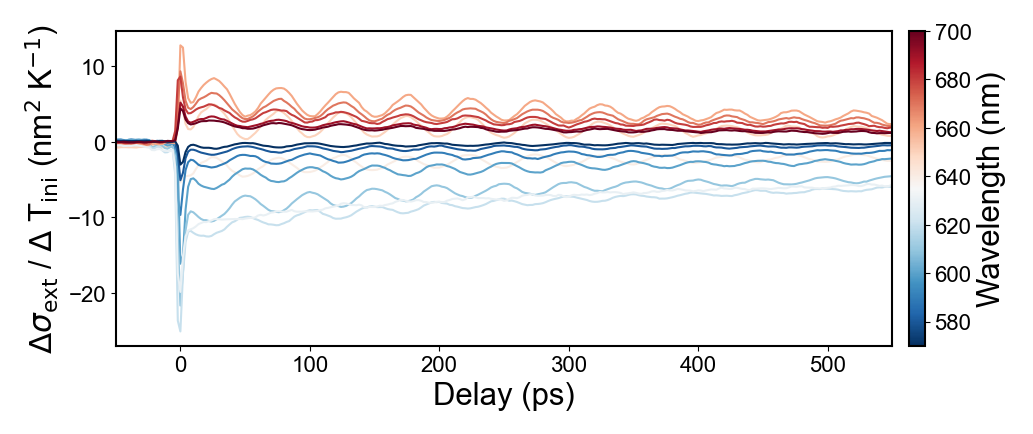

In [ ]:
fig, ax = plt.subplots(figsize=(18*cm*figsize_conversion_coeff, 8*cm*figsize_conversion_coeff))

# Collect lda_probe values
lda_values = np.array([All_traces[key].lda_probe for key in All_traces])

# Colormap and normalization (explicit range)
cmap = plt.get_cmap('copper')
cmap = plt.get_cmap('RdBu')
cmap = plt.get_cmap('seismic')
#cmap = plt.get_cmap('twilight')
cmap = plt.get_cmap('RdBu_r')
norm = plt.Normalize(vmin=lda_values.min(), vmax=lda_values.max())

# Plot traces
for key in All_traces:
    trace = All_traces[key]

    if norm(trace.lda_probe) <= 655 :
        dT = dT1
    else :
        dT = dT2
    ax.plot(
        trace.delay_tot,
        trace.DTT_tot*trace.dtt_to_sigma_ext_coeff/dT,
        color=cmap(norm(trace.lda_probe))
    )

# Create a ScalarMappable for the colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])  # required for older matplotlib versions

# Add colorbar on the side, tied to ax
cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02,      # distance from the plot
    fraction=0.05 # width of the colorbar
)

cbar.set_label(r'Wavelength (nm)', fontsize=28*fixed_factor)

ax.set_xlabel('Delay (ps)', fontsize=28*fixed_factor)
ax.set_ylabel(r'$\Delta \sigma_{\mathrm{ext}}$ / $\Delta$ T$_{\mathrm{ini}}$ (nm$^2$ K$^{-1}$)', fontsize=28*fixed_factor)
ax.set_xlim( (-50, 550))



fig.set_size_inches((19*cm*figsize_conversion_coeff, 8*cm*figsize_conversion_coeff))
plt.tight_layout()
plt.show()


fig.patch.set_facecolor( '#FF000000' )

if saving_figures :
    os.chdir(dir_save_data)
    plt.savefig('All raw PaP signals - ND2 zone1 thick silica.svg')
    plt.savefig('All raw PaP signals - ND2 zone1 thick silica.png')

Lda1 = 631.69 nm / Lda 2 = 631.69 nm / Lda2-Lda1 = 3.218e-03


Text(400, -2, '$\\Delta \\lambda$  = 3.218e-03 nm')

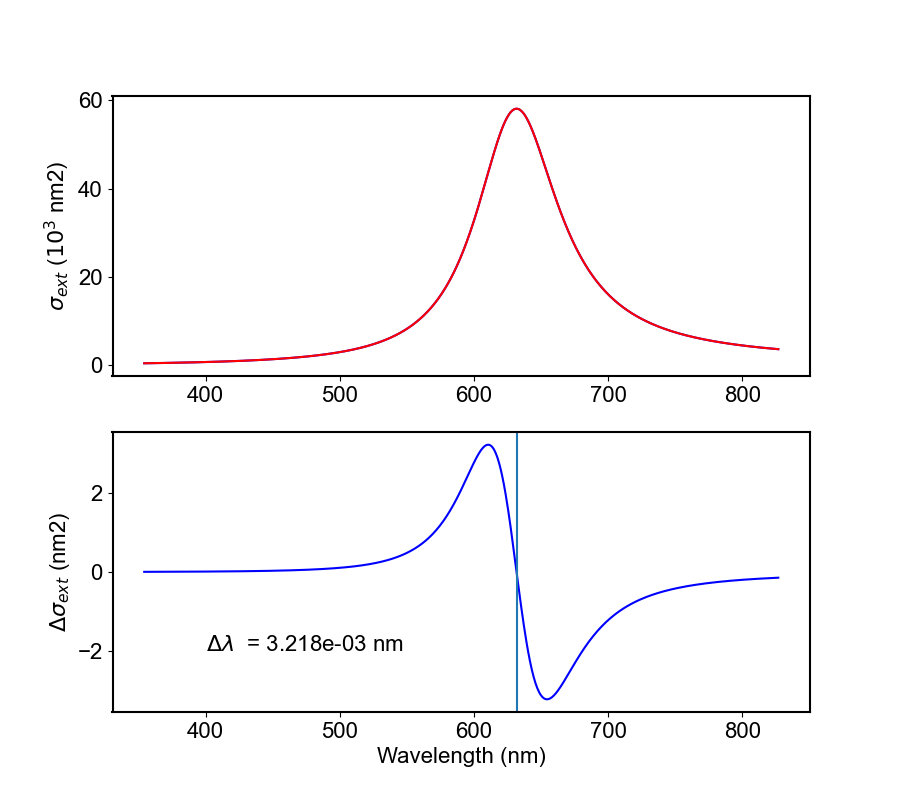

In [47]:
int1, w1, E1 = 21520e-18, 235.72e-3, 1240/631.69
A1 = int1/w1*2/np.pi

Energy = np.linspace(1.5, 3.5, 1000)

E2 = E1 + 1e-5
print('Lda1 = {:.2f} nm / Lda 2 = {:.2f} nm / Lda2-Lda1 = {:.3e}'.format(1240/E1, 1240/E2, 1240/E1-1240/E2))

fig, ax = plt.subplots(nrows=2, figsize=(9, 8))

ax[0].plot(1240/Energy, (Lorentz_no_offset(Energy, E1, w1, A1))*1e15, color='blue')
ax[0].plot(1240/Energy, (Lorentz_no_offset(Energy, E2, w1, A1))*1e15, color='red')
ax[0].set_ylabel(r'$\sigma_{ext}$ ($10^3$ nm2)')


ax[1].plot(1240/Energy, (Lorentz_no_offset(Energy, E2, w1, A1) - Lorentz_no_offset(Energy, E1, w1, A1))*1e18, color='blue')
ax[1].axvline(1240/E1)
ax[1].set_xlabel('Wavelength (nm)')
ax[1].set_ylabel(r'$\Delta \sigma_{ext}$ (nm2)')
ax[1].text(400, -2, r'$\Delta \lambda$  = {:.3e} nm'.format(1240/E1-1240/E2) )